# Zhang Cohort Validation


In [41]:
import os
import re
import sys
import pickle
import numpy as np
import pandas as pd
import scipy as sc
import matplotlib.pyplot as plt
from matplotlib.ticker import Locator, MaxNLocator
from matplotlib.colors import LogNorm, to_rgb
from matplotlib import colormaps
from lmfit import minimize, Parameters
from tqdm import tqdm

sys.path.append("../utils")
from myUtils import (convert_ode_parameters, calc_critical_treatment_threshold, calc_critical_treatment_interval, calc_average_overshoot,
                     ExtractTreatmentFromDf, predict_atx_ttp, predict_at_threshold_ttp, calc_delta_benefit, predict_ct_ttp, predict_drug_benefit)
from fittingUtils import residual, compute_r_sq, load_fit, generate_fitSummaryDf, perform_bootstrap
from plotUtils import PlotDrug, PlotData, convert_to_rgb_grayscale, redistribute_rgb
from odeModels import LotkaVolterraModel

In [2]:
# Defaults for plotting
plt.style.use(["classic", "../paper_figures/paper.mplstyle"])
plt.rcParams['font.size'] = '18'

colors = {'Sensitive': '#4c9150', 'Resistant': '#a80303', 'CT':'#c28d32' , 'AT':'#0044AA' ,'DRL_Monthly':'#66419e'}

In [3]:
file_path = os.path.dirname(os.path.abspath("__file__"))

In [4]:
def SimulateFit(fit_params, dataDf, dt=1, solver_kws={}):
    myModel = LotkaVolterraModel()
    myModel.SetParams(**fit_params)
    myModel.Simulate(treatmentScheduleList=ExtractTreatmentFromDf(dataDf),**solver_kws)
    # Interpolate to the desired time grid
    t_eval = np.arange(0, myModel.resultsDf.Time.max(), dt)
    trimmedResultsDic = {'Time': t_eval}
    for variable in ['S', 'R', 'TumourSize', 'DrugConcentration']:
        f = sc.interpolate.interp1d(myModel.resultsDf.Time, myModel.resultsDf[variable])
        trimmedResultsDic = {**trimmedResultsDic, variable: f(t_eval)}
    myModel.resultsDf = pd.DataFrame(trimmedResultsDic)
    return myModel

## Patient Datasets

In [5]:
data_path = "../patients/Zhang_et_al/at_patients/data"
solver_kws={'method':'RK45', 'absErr':1.0e-10, 'relErr':1.0e-10,
            'suppressOutputB':False}

df = pd.read_csv(os.path.join("patient_fits", "Zhang_full_history copy.csv"))
trunc_df = pd.read_csv(os.path.join("patient_fits", "Zhang_first_cycle copy.csv"))

patientIds = [1014, 1016, 1018]
df = df[df['PatientId'].isin(patientIds)]

n = len(df['PatientId'].unique())
cols = [colormaps['tab10'](i/n) for i in range(n)]
markers = ['v', 's', 'X', 'P', 'o', '*', 'd'] * int(n/7+1)



In [6]:
# Overwrite helperS function for this dataA format
def LoadPatientData(patientId, dataDir):
    patientDataDf = pd.read_csv(os.path.join(dataDir, "patient%.3d.csv" % patientId))
    patientDataDf.drop(labels='PSA', axis=1, inplace=True)
    patientDataDf.rename({'Days': 'Time', 'Abi': 'DrugConcentration',
                          'relPSA_Indi': 'PSA'}, axis=1, inplace=True)
    patientDataDf = patientDataDf.sort_values(by="Time")
    return patientDataDf

In [7]:
def TruncateDataframe(dataframe, drug_name = 'Abi'):
    """Select the first cycle from patient data.
    Modified version to ignore initial holiday periods"""
    drug_seq = ''.join([str(int(x)) for x in dataframe[drug_name].values])
    num_preceding_zeros = len(drug_seq) - len(drug_seq.lstrip('0'))
    end_ind = drug_seq.lstrip('0').find('01')
    return dataframe.head(end_ind + num_preceding_zeros + 1) if end_ind >= 0 else dataframe


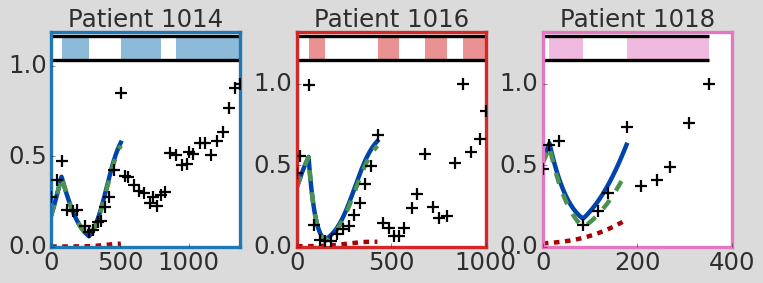

In [8]:
plt.rcParams['font.size'] = '22'
fig, axs = plt.subplots(1, len(patientIds), figsize=(10, 4))

for i, patientId in enumerate(patientIds):
    ax = axs.flatten()[i]
    dataDf = LoadPatientData(patientId, data_path)
    PlotData(dataDf, ax, drugBarPosition=max(dataDf.PSA)*1.15, drug_col=cols[i],
             drugBarHeight=max(dataDf.PSA)*0.15, zorder=10, markersize=10)
    
    patient_params = df[df['PatientId'] == patientId].iloc[0]
    treatment_schedule = ExtractTreatmentFromDf(dataDf)
    
    myModel = LotkaVolterraModel(); myModel.SetParams(**patient_params.to_dict())
    myModel.Simulate(treatmentScheduleList=treatment_schedule, **solver_kws)
    myModel.Trim(dt=1)
    df_temp = TruncateDataframe(myModel.resultsDf, drug_name = 'DrugConcentration')
    
    linestyles = ['-', (0, (10,10)), (0, (5,5))]
    col_vars = ['AT', 'Sensitive', 'Resistant']       
    for j, var in enumerate(["TumourSize", 'S', 'R']):
        ax.plot(df_temp['Time'], df_temp[var], linewidth=4, linestyle=linestyles[j], color=colors[col_vars[j]])
        # ax.plot(myModel.resultsDf['Time'], myModel.resultsDf[var], linewidth=4, linestyle=linestyles[j], color='gray', alpha=0.5)
    ax.legend().remove()
    
    ax.set_title("Patient " + str(patientId), size=22)
    ax.set_yticks([0, 0.5, 1])
    
    ax.set_xlim(0, max(myModel.resultsDf['Time']))
    x_ticks = [0, 200, 400] if patientId == 1018 else [0, 500, 1000]
    ax.set_xticks(x_ticks)
    
    ax.set_ylim(0, max(dataDf.PSA) * 1.32)
    if len(ax.get_yticks()) > 7:
        ax.set_yticks(ax.get_yticks()[::2])
    ax.set_yticks([x for x in ax.get_yticks() if x < max(dataDf.PSA) * 1.15])

    for loc in ['bottom', 'left', 'top', 'right']:
        ax.spines[loc].set_color(cols[i])
        ax.spines[loc].set_linewidth(3)
    
plt.tight_layout()
plt.subplots_adjust(hspace=0.3, wspace=0.3)
plt.savefig("figures/Zhang_trunc_summary.pdf", dpi=300, bbox_inches='tight')

## Variation in Patient Thresholds


In [9]:
df['Cost'] = 1 - df['rR'] / df['rS']
df['Turnover'] = df['dS'] / df['rS']

In [10]:
# Compare the effictiveness of different AT threshold strategies for progression patients

def at_treat(model, t_max, at_threshold=0.5, intervalLength = 1, **kwargs):
    model.Simulate_AT(atThreshold=at_threshold, intervalLength=intervalLength, t_end=t_max)
    if max(model.resultsDf['Time']) == t_max:
        print("Warning - t_max may be insufficient for progression under AT strategy")
    return max(model.resultsDf['Time'])

threshold_list = np.arange(0.1, 1.0, 0.1)
t_max = 5000

def at_model(id, t_max, at_threshold):
    model = LotkaVolterraModel(method='RK45', dt=1)
    model.SetParams(**df[df.PatientId == id].iloc[0].to_dict())
    return at_treat(model, t_max=t_max, at_threshold=at_threshold)

for threshold in tqdm(threshold_list):
    col_name = 'AT_Threshold_' + str(threshold)
    df[col_name] = df["PatientId"].apply(at_model, args = (t_max, threshold))

100%|██████████| 9/9 [00:07<00:00,  1.24it/s]


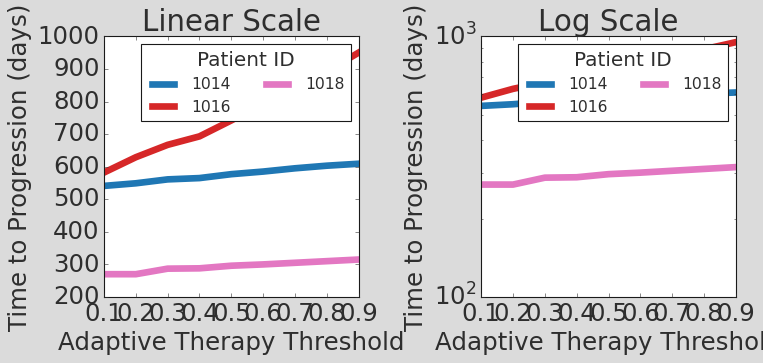

In [11]:
# Define column names based on threshold_list
col_names = ['AT_Threshold_' + str(num) for num in threshold_list]

# Create subplots
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5))

for (ax, scale) in zip([ax1, ax2], ['linear', 'log']):
    # Plot data on the first subplot with a log scale
    for n, id in enumerate(df['PatientId'].sort_values()):
        ax.plot(threshold_list, df.loc[df['PatientId'] == id, col_names].values[0], 
                label=id, color=cols[n], linewidth=6)

    ax.set_yscale(scale)
    ax.set_xlabel("Adaptive Therapy Threshold")
    ax.set_ylabel("Time to Progression (days)")
    ax.legend(title="Patient ID", ncol=2, fontsize=14, title_fontsize=18)
    ax.set_title(f"L{scale[1:]} Scale")

# Show the plot
plt.tight_layout()
plt.show()

Patient 1003 gets by far the largest benefit in absolute TTP. However, the log scale also emphasises that all patients benefit, with some receieving comparable relative benefits to AT.

## Variation in importance of tau

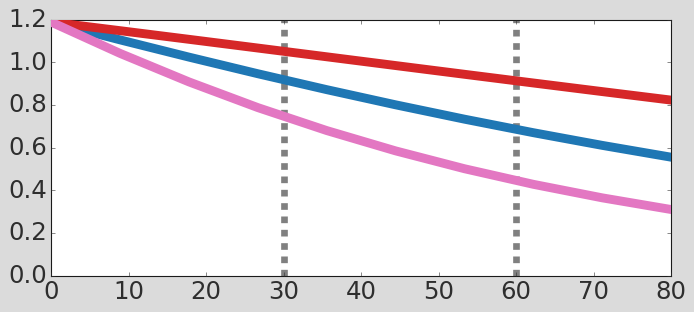

In [12]:
fig, ax = plt.subplots(1,1,figsize=(10,4))
for n, patient_id in enumerate(patientIds):
    odeParamDic = trunc_df[trunc_df.PatientId == patient_id].iloc[0].to_dict()

    tau_values = np.linspace(0, 80, 10)
    n_stars = [calc_critical_treatment_threshold(tau=t,**odeParamDic)
               / trunc_df[trunc_df.PatientId == patient_id].n0.iloc[0] for t in tau_values]
    ax.plot(tau_values, n_stars, linewidth = 8, color=cols[n], zorder=5)


ax.vlines(ymin=0, ymax=1.2, x=30, linestyles="--", linewidth=6, color="gray")
ax.vlines(ymin=0, ymax=1.2, x=60, linestyles="--", linewidth=6, color="gray")

# plt.ylim(-0.01,1.2)
# plt.xlabel("Decision Interval"); plt.ylabel("Analytic Threshold");
plt.savefig("figures/fig5c_selected_n_crit.pdf")

In [13]:
def calc_best_ttp(params, interval):
    n_crit = calc_critical_treatment_threshold(tau = interval, **params)
    arg = n_crit/params['n0']
    # print(n_crit, arg, interval)
    model = LotkaVolterraModel(dt=1); model.SetParams(**params)
    model.Simulate_AT(atThreshold=arg, atMethod='Threshold',
                    intervalLength=interval, t_end=5000, refSize = params['n0'])
    model.resultsDf = model.resultsDf[model.resultsDf.TumourSize < 1.2 * params['n0']]
    # model.Plot(plotPops=True, legend=False)
    # plt.gcf().get_axes()[0].get_legend().remove()
    return model.resultsDf.Time.max()

## TTP Prediction

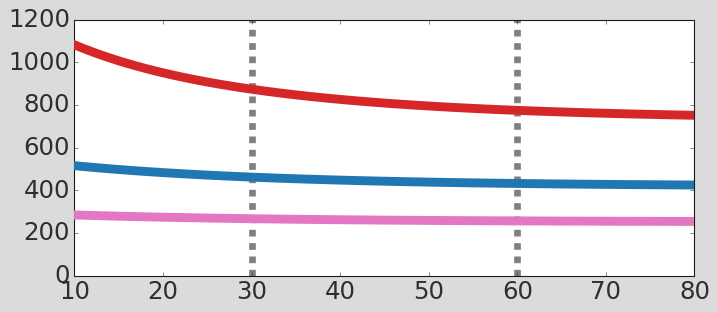

In [14]:
fig, ax = plt.subplots(1,1,figsize=(10,4))
for n, patient_id in enumerate(patientIds):
    odeParamDic = trunc_df[trunc_df.PatientId == patient_id].iloc[0].to_dict()

    tau_values = np.linspace(0, 80, 81)
    ttp_est = [predict_atx_ttp(tau=t,**odeParamDic) for t in tau_values]
    ttp_est = [predict_atx_ttp(tau=t, upper = odeParamDic['n0'] * 0.2, n_lim = odeParamDic['n0']*0.6, **odeParamDic) for t in tau_values]

    ax.plot(tau_values, ttp_est, linewidth = 8, color=cols[n], zorder=5)

y_max = plt.gca().get_ylim()[1]
ax.vlines(ymin=0, ymax=y_max, x=30, linestyles="--", linewidth=6, color="gray")
ax.vlines(ymin=0, ymax=y_max, x=60, linestyles="--", linewidth=6, color="gray")

plt.xlim(left=10); plt.ylim(0, 1200)
# plt.xlabel("Decision Interval"); plt.ylabel("TTP estimate");
plt.savefig("figures/fig5c_selected_ettp.pdf")

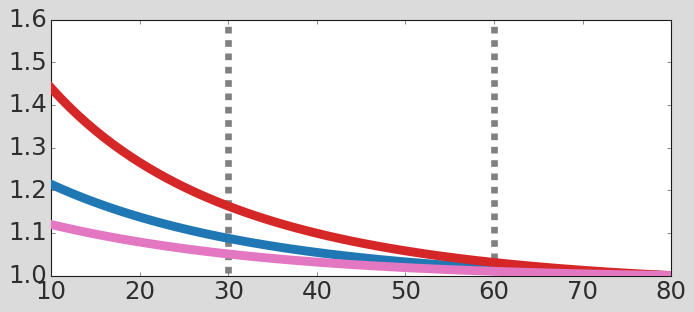

In [15]:
# Predicted benefit over CT TTP

fig, ax = plt.subplots(1,1,figsize=(10,4))
for n, patient_id in enumerate(patientIds):
    odeParamDic = trunc_df[trunc_df.PatientId == patient_id].iloc[0].to_dict()

    tau_values = np.linspace(0, 80, 81)
    ct = predict_ct_ttp(**odeParamDic); ct=1
    ttp_est = [predict_atx_ttp(tau=t, upper = odeParamDic['n0'] * 0.2, n_lim = odeParamDic['n0']*0.6,**odeParamDic)/ct for t in tau_values]
    ttp_est = [x/ttp_est[-1] for x in ttp_est]
    ax.plot(tau_values, ttp_est, linewidth = 8, color=cols[n], zorder=5)

y_max = plt.gca().get_ylim()[1]
ax.vlines(ymin=0, ymax=y_max, x=30, linestyles="--", linewidth=6, color="gray")
ax.vlines(ymin=0, ymax=y_max, x=60, linestyles="--", linewidth=6, color="gray")

plt.xlim(left=10); plt.ylim(1, 1.6)
# plt.xlabel("Decision Interval"); plt.ylabel("TTP Benefit");
plt.savefig("figures/fig5c_selected_ttp_benefit.pdf")

3it [00:01,  2.64it/s]


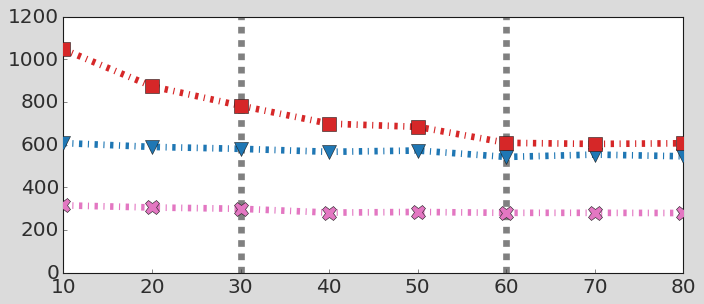

In [16]:
subsampled_tau_values = tau_values[10::10]

plt.rcParams['font.size'] = '18'
fig, ax = plt.subplots(1,1,figsize=(10,4))
for n, patient_id in tqdm(enumerate(patientIds)):
    odeParamDic = df[df.PatientId == patient_id].iloc[0].to_dict()

    ttp_vals = [calc_best_ttp(odeParamDic, int(t)) for t in subsampled_tau_values]

    ax.plot(subsampled_tau_values, ttp_vals, linewidth=6, linestyle='-.', color=cols[n],
            zorder=5, label="Patient " + str(patient_id), marker=markers[n], markersize=13)

ax.set_ylim(0, 1200)
ax.vlines(ymin=0, ymax=ax.get_ylim()[1], x=30, linestyles="--", linewidth=6, color="gray")
ax.vlines(ymin=0, ymax=ax.get_ylim()[1], x=60, linestyles="--", linewidth=6, color="gray")
ax.tick_params(right = False, top = False)

# plt.xlabel("Decision Interval"); plt.ylabel("TTP (days)");
plt.savefig("figures/fig5d_selected_max_ttp.pdf")

## Sensitivity to variation in Tau

In [17]:
def calc_noisy_ttp(params, interval, noise):
    # print(noise)
    n_crit = calc_critical_treatment_threshold(tau = interval, **params)
    arg = n_crit/params['n0']
    model = LotkaVolterraModel(dt=1); model.SetParams(**params)
    model.Simulate_AT(atThreshold=arg, atMethod='Threshold',
                    intervalLength=interval, t_end=5000, refSize = params['n0'],
                    useRandomInterval=True, noiseFrac=noise)
    model.resultsDf = model.resultsDf[model.resultsDf.TumourSize < 1.2 * params['n0']]
    return model.resultsDf.Time.max()

100%|██████████| 20/20 [00:13<00:00,  1.48it/s]


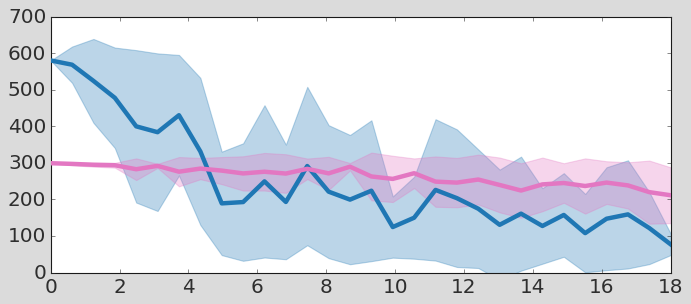

In [18]:
noise_vals = np.linspace(0, 0.6, 30)
n_reps = 20

np.random.seed(1)

plt.rcParams['font.size'] = '18'
fig, ax = plt.subplots(1,1,figsize=(10,4))
# for n, patient_id in enumerate(patientIds):  # specified IDs from keep_ids
for n, patient_id in enumerate([1014, 1018]):  # specified IDs from keep_ids
    patient_index = np.where(np.array(patientIds) == patient_id)[0][0]

    ttp_repeats = []
    odeParamDic = df[df.PatientId == patient_id].iloc[0].to_dict()
    for p in tqdm(range(n_reps)):
        ttp_repeats.append([calc_noisy_ttp(odeParamDic, 30, noise) for noise in noise_vals])
    ttp_vals = np.mean(ttp_repeats, axis=0)
    ax.plot([30*x for x in noise_vals], ttp_vals, linewidth = 4, 
            color=cols[patient_index], zorder=5, alpha=1)
    ttp_std = np.std(ttp_repeats, axis=0)
    ax.fill_between([30*x for x in noise_vals], ttp_vals - ttp_std, ttp_vals + ttp_std,
                    alpha=0.3, color=cols[patient_index])
        
# plt.xlabel("Noise Term / Decision Interval"); plt.ylabel("TTP (days)");
# plt.legend(ncol=2, loc=1, fontsize=18); 
plt.ylim(bottom=0)
plt.savefig("figures/fig5de_tau_sensitivity_shading4.pdf")

100%|██████████| 20/20 [00:11<00:00,  1.67it/s]


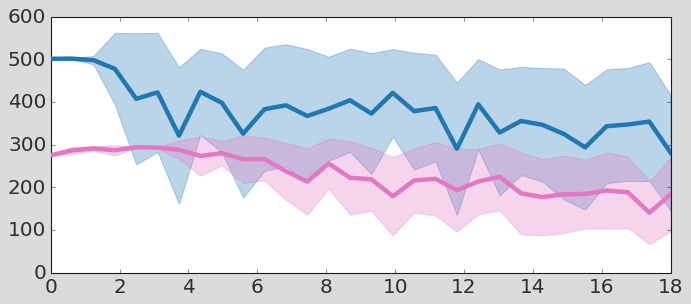

In [19]:
noise_vals = np.linspace(0, 0.6, 30)
n_reps = 20

np.random.seed(1)

plt.rcParams['font.size'] = '18'
fig, ax = plt.subplots(1,1,figsize=(10,4))
# for n, patient_id in enumerate(patientIds):  # specified IDs from keep_ids
for n, patient_id in enumerate([1014, 1018]):  # specified IDs from keep_ids
    patient_index = np.where(np.array(patientIds) == patient_id)[0][0]

    ttp_repeats = []
    odeParamDic = trunc_df[trunc_df.PatientId == patient_id].iloc[0].to_dict()
    for p in tqdm(range(n_reps)):
        ttp_repeats.append([calc_noisy_ttp(odeParamDic, 30, noise) for noise in noise_vals])
    ttp_vals = np.mean(ttp_repeats, axis=0)
    ax.plot([30*x for x in noise_vals], ttp_vals, linewidth = 4, 
            color=cols[patient_index], zorder=5, alpha=1)
    ttp_std = np.std(ttp_repeats, axis=0)
    ax.fill_between([30*x for x in noise_vals], ttp_vals - ttp_std, ttp_vals + ttp_std,
                    alpha=0.3, color=cols[patient_index])
        
# plt.xlabel("Noise Term / Decision Interval"); plt.ylabel("TTP (days)");
# plt.legend(ncol=2, loc=1, fontsize=18); 
plt.ylim(bottom=0)
plt.savefig("figures/fig5de_tau_sensitivity_shading4_trunc.pdf")

## Biomarker Scores

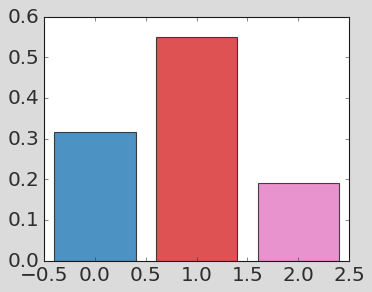

In [26]:
plt.rcParams['font.size'] = '18'
fig, ax = plt.subplots(1,1 ,figsize=(5,4))
    
def doubling_benefit_wrapper(row):
    kappa = 0.7 * row.n0 / row.K  
    return calc_delta_benefit(kappa=kappa, **row.to_dict())
  
doubling = [doubling_benefit_wrapper(trunc_df[trunc_df.PatientId == n].iloc[0])
            for n in patientIds]


plt.bar(range(len(doubling)), doubling, color=[cols[n] for n in range(len(doubling))], alpha=0.8)

plt.tight_layout()
plt.savefig("figures/fig5_delta_at_scores.pdf")

[0 1 2] [np.float64(0.3156440735579794), np.float64(0.5502143830945524), np.float64(0.19041986810207367)]


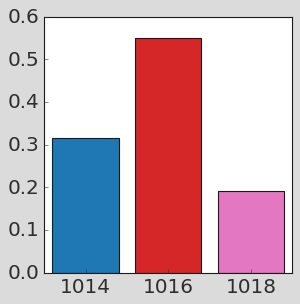

In [27]:
plt.rcParams['font.size'] = '18'
fig, ax = plt.subplots(1,1,figsize=(4,4))
ids = np.array(range(len(patientIds)))
df_n = trunc_df[trunc_df.PatientId.isin(patientIds)]

doubling = [calc_delta_benefit(kappa =  0.7 * df_n[df_n.PatientId == n].n0.values[0] / df_n[df_n.PatientId == n].K.values[0], \
    **df_n[df_n.PatientId == n].iloc[0].to_dict())
    for n in df_n.PatientId]

print(ids, doubling)
ax.bar(ids, doubling, color=cols, width=0.8)
ax.set_xticks(ids, df_n.PatientId)
ax.set_xlim(-0.5, 2.5), ax.set_ylim(bottom=0);
ax.tick_params(top=False, right=False)
plt.savefig("figures/fig5_delta_at_scores_bar.pdf")

[0 1 2] [np.float64(0.2917824428999804), np.float64(0.83842575534329), np.float64(0.5189151590696723)]
[0 1 2] [np.float64(0.6986140224824108), np.float64(1.5539469023868986), np.float64(0.37782344663685474)]


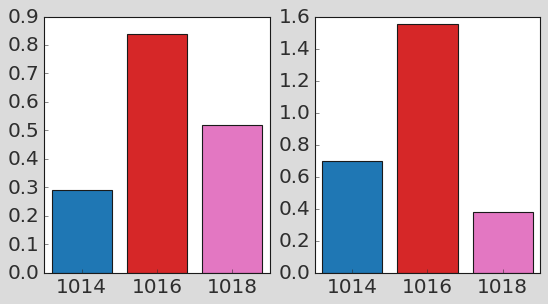

In [28]:
plt.rcParams['font.size'] = '18'
fig, axs = plt.subplots(1,2,figsize=(8,4))

for ax, df_n in zip(axs, [df, trunc_df]):
  df_n = df_n[df_n.PatientId.isin(patientIds)]
  # kappa = 0.5 * row.n0 / row.K  # 50% threshold, accounting for kappa scaling
  doubling = [calc_delta_benefit(kappa = 0.2, # 0.5 * df_n[df_n.PatientId == n].n0.values[0] / df_n[df_n.PatientId == n].K.values[0], \
     **df_n[df_n.PatientId == n].iloc[0].to_dict())
       for n in df_n.PatientId]
  print(ids, doubling)
  ax.bar(ids, doubling, color=cols, width=0.8)
  ax.set_xticks(ids, df_n.PatientId)
  ax.set_xlim(-0.5, 2.5), ax.set_ylim(bottom=0);
  ax.tick_params(top=False, right=False)
# ax.set_xlabel("Patient ID"); ax.set_ylabel("Crit Threshold (days)");
# plt.legend(loc=1, fontsize=14, numpoints=1)
# plt.gca().legend(loc=1, fontsize=18, numpoints=1).get_frame().\
  # set_boxstyle('Round', pad=0.2, rounding_size=0.5)

In [29]:
exp_ct = [predict_ct_ttp(**trunc_df[trunc_df.PatientId == n].iloc[0].to_dict()) for n in patientIds]
exp_at = [predict_at_threshold_ttp(tau=60, **trunc_df[trunc_df.PatientId == n].iloc[0].to_dict()) for n in patientIds]
exp_at_plus = [predict_at_threshold_ttp(tau=30, **trunc_df[trunc_df.PatientId == n].iloc[0].to_dict()) for n in patientIds]

In [32]:
def predict_at_window_ttp(tau, n_crit, **kwargs):
    params = kwargs
    n_overshoot = calc_average_overshoot(tau, n_crit, **params)
    ave_n = ((n_crit + 1.2 * params['n0'])/2 - n_overshoot)
    benefit = calc_delta_benefit(kappa=(ave_n / params['K']), **params)
    ct_ttp = predict_ct_ttp(**params)
    return ct_ttp * (1 + benefit)

In [33]:
exp_ct = [predict_ct_ttp(**trunc_df[trunc_df.PatientId == n].iloc[0].to_dict()) for n in patientIds]
exp_at = [predict_at_window_ttp(tau=21, n_crit=0.5 * df_n[df_n.PatientId == n].n0.values[0],
                                 **trunc_df[trunc_df.PatientId == n].iloc[0].to_dict()) for n in patientIds]
exp_at_plus = [predict_at_window_ttp(tau=21, n_crit=0.9 * df_n[df_n.PatientId == n].n0.values[0],
                                      **trunc_df[trunc_df.PatientId == n].iloc[0].to_dict()) for n in patientIds]

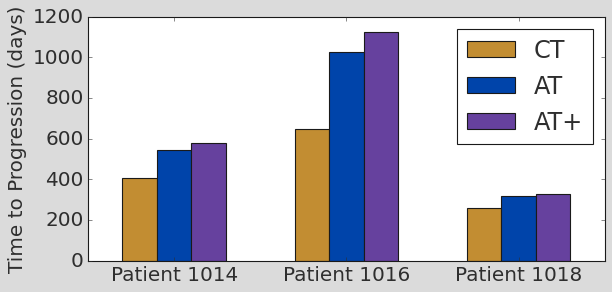

In [34]:
plt.rcParams['font.size'] = '18'
fig, ax = plt.subplots(1,1 ,figsize=(8,4))
    
labels = ['CT', 'AT', 'AT+']
width = 0.2  # width of the bars

x = np.arange(len(patientIds))  # the label locations

# Plot bars for each strategy
ax.bar(x - width, exp_ct, width, label='CT', color=colors['CT'])
ax.bar(x, exp_at, width, label='AT', color=colors['AT'])
ax.bar(x + width, exp_at_plus, width, label='AT+', color=colors['DRL_Monthly'])

# Add labels, title, and legend
ax.set_xticks(x)
ax.set_xticklabels([f"Patient {pid}" for pid in patientIds])
ax.set_ylabel("Time to Progression (days)")
ax.legend()

plt.tight_layout()
plt.savefig("figures/fig5_eTTP_scores.pdf")

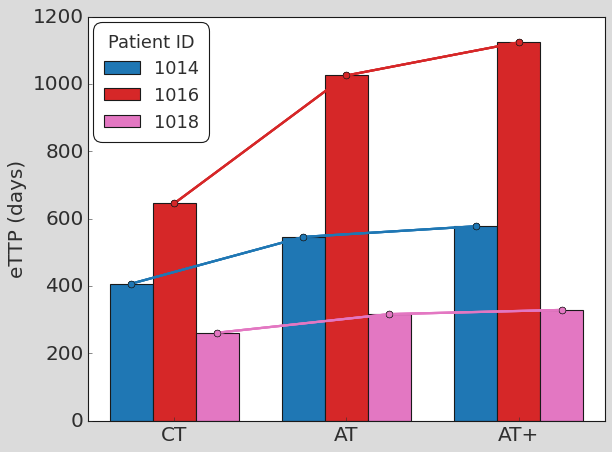

In [35]:
# Define the positions for the bars
x = np.arange(len(labels))  # CT, AT, AT+
width = 0.25  # width of the bars

# Create the plot
plt.rcParams['font.size'] = '18'
fig, ax = plt.subplots(figsize=(8, 6))

# Plot bars for each patient
for i, patient_id in enumerate(patientIds):
    ax.bar(x + i * width, [exp_ct[i], exp_at[i], exp_at_plus[i]], width, label=patient_id, color=cols[i])
    # Add lines joining the tops of each bar
    for i in range(len(patientIds)):
        ax.plot(x + i * width, [exp_ct[i], exp_at[i], exp_at_plus[i]], color=cols[i], linewidth=2, marker='o')

# Add labels, title, and legend
ax.set_xticks(x + width)
ax.set_xticklabels(labels)
ax.set_xlim(-0.25, len(labels)-0.25)
ax.set_ylabel("eTTP (days)")
# ax.set_title("Comparison of CT, AT, and AT+ Strategies")
legend = ax.legend(title="Patient ID", fontsize=16, title_fontsize=16, loc=2)
legend.get_frame().set_boxstyle('Round', pad=0.2, rounding_size=0.5)

ax.tick_params(top=False, right=False)

# Show the plot
plt.tight_layout()
plt.savefig("figures/fig5_eTTP_scores_grouped.pdf")
plt.show()

/var/folders/sr/x0nw2n7d0fjbff6xwtl6dbs80000gn/T/ipykernel_20513/4010754362.py:20: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend().remove()
/var/folders/sr/x0nw2n7d0fjbff6xwtl6dbs80000gn/T/ipykernel_20513/4010754362.py:20: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend().remove()
/var/folders/sr/x0nw2n7d0fjbff6xwtl6dbs80000gn/T/ipykernel_20513/4010754362.py:20: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend().remove()


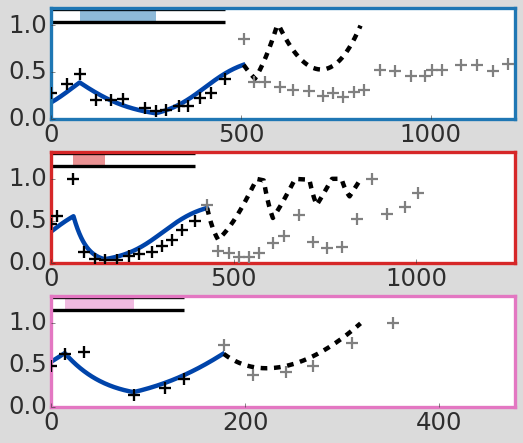

In [23]:
plt.rcParams['font.size'] = '22'
fig, axs = plt.subplots(len(patientIds), 1, figsize=(7, 6))

for i, patientId in enumerate(patientIds):
    ax = axs.flatten()[i]
    dataDf = LoadPatientData(patientId, data_path)
    
    patient_params = df[df['PatientId'] == patientId].iloc[0]
    treatment_schedule = ExtractTreatmentFromDf(dataDf)
    
    myModel = LotkaVolterraModel(); myModel.SetParams(**patient_params.to_dict())
    myModel.Simulate(treatmentScheduleList=treatment_schedule, **solver_kws)
    myModel.Trim(dt=1)
    df_temp = TruncateDataframe(myModel.resultsDf, drug_name = 'DrugConcentration')
    
    linestyles = ['-', (0, (10,10)), (0, (5,5))]
    col_vars = ['AT', 'Sensitive', 'Resistant']       
    for j, var in enumerate(["TumourSize"]):
        ax.plot(df_temp['Time'], df_temp[var], linewidth=4, linestyle=linestyles[j], color=colors[col_vars[j]])
    ax.legend().remove()
    
    data_temp = TruncateDataframe(dataDf, drug_name = 'DrugConcentration')
    PlotData(dataDf, ax, drugBarPosition=max(dataDf.PSA)*1.15, drug_col=None,
            drugBarHeight=max(dataDf.PSA)*0.15, zorder=10, markersize=10, color='gray')
    PlotData(data_temp, ax, drugBarPosition=max(dataDf.PSA)*1.15, drug_col=cols[i],
            drugBarHeight=max(dataDf.PSA)*0.15, zorder=10, markersize=10)
    
    updated_params = patient_params.to_dict()
    # updated_params['N0'] = df_temp['TumourSize'].iloc[-1]
    updated_params['S0'] = df_temp['S'].iloc[-1]
    updated_params['R0'] = df_temp['R'].iloc[-1]
    
    updated_params['K'] *= 1 * max(dataDf['PSA']) / updated_params['n0']

    
    updatedModel = LotkaVolterraModel(); updatedModel.SetParams(**updated_params)
    
    if patientId == 1014:
        updatedModel.Simulate_AT(atThreshold=0.5, atMethod='Zhang', tumourSizeWhenProgressed=1.2 / updated_params['n0'], 
                                intervalLength=30, t_end=2000, refSize=1)
    elif patientId == 1016:
        updatedModel.Simulate_AT(atThreshold=0.8, atMethod='Zhang', tumourSizeWhenProgressed=1.2 / updated_params['n0'],
                                intervalLength=30, t_end=2000, refSize=1)
        # updatedModel.resultsDf['TumourSize'] *= (updatedModel.resultsDf['TumourSize'].iloc[0] / updated_params['n0'])

    elif patientId == 1018:
        
        updatedModel.Simulate([[0, 2000, 1]])
    else:
        raise ValueError("Unknown patient ID: {}".format(patientId))
    updatedModel.Trim(dt=1)
    
    # max_Nt = max(dataDf['TumourSize']) * 1.2
    updatedModel.resultsDf = updatedModel.resultsDf[updatedModel.resultsDf.TumourSize < 1]
    
    updatedModel.resultsDf.Time += df_temp['Time'].iloc[-1] + 1
    ax.plot(updatedModel.resultsDf['Time'], updatedModel.resultsDf['TumourSize'], 
            linewidth=4, linestyle='--', color='black', label="AT Prediction")
    

    ax.set_yticks([0, 0.5, 1])
    
    ax.set_xlim(0, max(updatedModel.resultsDf['Time'])*1.5)
    x_ticks = [0, 200, 400] if patientId == 1018 else [0, 500, 1000]
    ax.set_xticks(x_ticks)
    
    ax.set_ylim(0, max(dataDf.PSA) * 1.32)
    if len(ax.get_yticks()) > 7:
        ax.set_yticks(ax.get_yticks()[::2])
    ax.set_yticks([x for x in ax.get_yticks() if x < max(dataDf.PSA) * 1.15])

    for loc in ['bottom', 'left', 'top', 'right']:
        ax.spines[loc].set_color(cols[i])
        ax.spines[loc].set_linewidth(3)
    
plt.tight_layout()
plt.subplots_adjust(hspace=0.3, wspace=0.3)
plt.savefig("figures/Zhang_trunc_futures.pdf", dpi=300, bbox_inches='tight')

/var/folders/sr/x0nw2n7d0fjbff6xwtl6dbs80000gn/T/ipykernel_20513/3250848247.py:20: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend().remove()
/var/folders/sr/x0nw2n7d0fjbff6xwtl6dbs80000gn/T/ipykernel_20513/3250848247.py:20: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend().remove()
/var/folders/sr/x0nw2n7d0fjbff6xwtl6dbs80000gn/T/ipykernel_20513/3250848247.py:20: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend().remove()


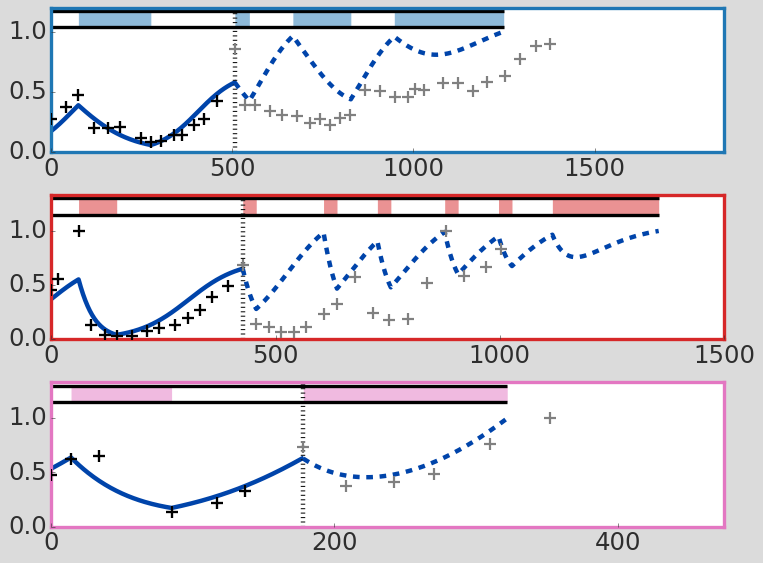

In [24]:
plt.rcParams['font.size'] = '22'
fig, axs = plt.subplots(len(patientIds), 1, figsize=(10, 7.5))

for i, patientId in enumerate(patientIds):
    ax = axs.flatten()[i]
    dataDf = LoadPatientData(patientId, data_path)
    
    patient_params = df[df['PatientId'] == patientId].iloc[0]
    treatment_schedule = ExtractTreatmentFromDf(dataDf)
    
    myModel = LotkaVolterraModel(); myModel.SetParams(**patient_params.to_dict())
    myModel.Simulate(treatmentScheduleList=treatment_schedule, **solver_kws)
    myModel.Trim(dt=1)
    df_temp = TruncateDataframe(myModel.resultsDf, drug_name = 'DrugConcentration')
    
    linestyles = ['-', (0, (10,10)), (0, (5,5))]
    col_vars = ['AT', 'Sensitive', 'Resistant']       
    for j, var in enumerate(["TumourSize"]):
        ax.plot(df_temp['Time'], df_temp[var], linewidth=4, linestyle=linestyles[j], color=colors[col_vars[j]])
    ax.legend().remove()
    
    data_temp = TruncateDataframe(dataDf, drug_name = 'DrugConcentration')
    PlotData(dataDf, ax, drugBarPosition=max(dataDf.PSA)*1.15, drug_col=None,
            drugBarHeight=max(dataDf.PSA)*0.15, zorder=10, markersize=10, color='gray')
    PlotData(data_temp, ax, drugBarPosition=max(dataDf.PSA)*1.15, drug_col=None,
            drugBarHeight=max(dataDf.PSA)*0.15, zorder=10, markersize=10)
    ax.axvline(x=df_temp['Time'].iloc[-1]+1, color='k', linestyle=':', linewidth=4)
    
    updated_params = patient_params.to_dict()
    updated_params['n0'] = df_temp['TumourSize'].iloc[-1]
    updated_params['S0'] = df_temp['S'].iloc[-1]
    updated_params['R0'] = df_temp['R'].iloc[-1]
    
    updated_params['K'] *= 1.1 * max(dataDf['PSA']) / updated_params['n0']

    
    updatedModel = LotkaVolterraModel(); updatedModel.SetParams(**updated_params)
    
    if patientId == 1014:
        updatedModel.Simulate_AT(atThreshold=0.5, atMethod='Zhang', tumourSizeWhenProgressed=1.2 / updated_params['n0'], 
                                intervalLength=20, t_end=2000, refSize=0.9)
    elif patientId == 1016:
        updatedModel.Simulate_AT(atThreshold=0.8, atMethod='Zhang', tumourSizeWhenProgressed=1.2 / updated_params['n0'],
                                intervalLength=30, t_end=2000, refSize=0.9)
        # updatedModel.resultsDf['TumourSize'] *= (updatedModel.resultsDf['TumourSize'].iloc[0] / updated_params['n0'])

    elif patientId == 1018:
        
        updatedModel.Simulate([[0, 2000, 1]])
    else:
        raise ValueError("Unknown patient ID: {}".format(patientId))
    updatedModel.Trim(dt=1)
    
    # max_Nt = max(dataDf['TumourSize']) * 1.2
    updatedModel.resultsDf = updatedModel.resultsDf[updatedModel.resultsDf.TumourSize < 1]
    
    updatedModel.resultsDf.Time += df_temp['Time'].iloc[-1] + 1
    ax.plot(updatedModel.resultsDf['Time'], updatedModel.resultsDf['TumourSize'], 
            linewidth=4, linestyle='--', color=colors['AT'], label="AT Prediction")
    
    comb_df = pd.concat([df_temp, updatedModel.resultsDf], ignore_index=True)
    PlotDrug(comb_df, ax, currDrugBarPosition=max(dataDf.PSA)*1.15, 
             color=cols[i], drugBarHeight=max(dataDf.PSA)*0.15)
    

    ax.set_yticks([0, 0.5, 1])
    

    ax.set_xlim(0, max(dataDf['Time']) * 1.35)
    x_ticks = [0, 200, 400] if patientId == 1018 else [0, 500, 1000, 1500]
    ax.set_xticks(x_ticks)
    
    ax.set_ylim(0, max(dataDf.PSA) * 1.33)
    if len(ax.get_yticks()) > 7:
        ax.set_yticks(ax.get_yticks()[::2])
    ax.set_yticks([x for x in ax.get_yticks() if x < max(dataDf.PSA) * 1.15])

    for loc in ['bottom', 'left', 'top', 'right']:
        ax.spines[loc].set_color(cols[i])
        ax.spines[loc].set_linewidth(3)
    
plt.tight_layout()
plt.subplots_adjust(hspace=0.3, wspace=0.3)
plt.savefig("figures/Zhang_trunc_futures.pdf", dpi=300, bbox_inches='tight')

## Drug Dose

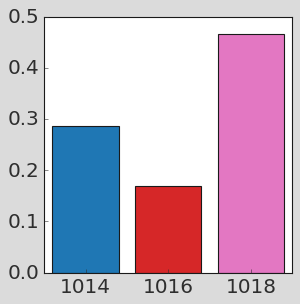

In [38]:
plt.rcParams['font.size'] = '18'
fig, ax = plt.subplots(1,1,figsize=(4,4))
ids = np.array(range(len(patientIds)))

mdd_vals= [predict_drug_benefit(tau=30, n_crit = 0.5 * trunc_df[trunc_df.PatientId == n].n0.values[0],
                                 **trunc_df[trunc_df.PatientId == n].iloc[0].to_dict())
    for n in patientIds]

ax.bar(ids, mdd_vals, color=cols, width=0.8)
ax.set_xticks(ids, patientIds)
ax.set_xlim(-0.5, 2.5), ax.set_ylim(bottom=0);
ax.tick_params(top=False, right=False)
plt.savefig("figures/fig5_eMMD_scores_bar.pdf")

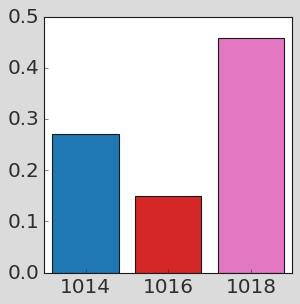

In [39]:
plt.rcParams['font.size'] = '18'
fig, ax = plt.subplots(1,1,figsize=(4,4))
ids = np.array(range(len(patientIds)))
df_n = trunc_df[trunc_df.PatientId.isin(patientIds)]

mdd_vals= [predict_drug_benefit(tau=10, n_crit = 0.75 * df_n[df_n.PatientId == n].n0.values[0],
                                 **df_n[df_n.PatientId == n].iloc[0].to_dict())
    for n in patientIds]

ax.bar(ids, mdd_vals, color=cols, width=0.8)
ax.set_xticks(ids, patientIds)
ax.set_xlim(-0.5, 2.5), ax.set_ylim(bottom=0);
ax.tick_params(top=False, right=False)
plt.savefig("figures/fig5_eMMD_scores_bar.pdf")